## 02 · The Rulebook

Notebook 01 showed that the battery can't carry the village through the evening alone; diesel has to fill the gap. This notebook introduces the first operator, a fixed set of rules written in advance, and measures how much diesel it burns to keep the lights on. Its results become the benchmark the AI has to beat.

In [1]:
# Load the environment, the rulebook operator, the episode runner and the day-plot helper
import matplotlib.pyplot as plt
from minigrid_mdp.env.minigrid_env import MiniGridEnv
from minigrid_mdp.agents import RuleBasedAgent
from minigrid_mdp.runner import run_episode
from minigrid_mdp.plotting import plot_day

env = MiniGridEnv()
rulebook = RuleBasedAgent(env.action_space)

### The rules

The rulebook looks at two things each hour, how much solar is available and how full the battery is, and follows these rules in order:

1. **If solar output is above 5 kW** → use `solar_only`, whatever the battery level. Surplus charges the battery; shortfalls are covered by it.
2. **After dark, battery above 50%** → `discharge_battery`, so the battery serves demand.
3. **After dark, battery between 30% and 50%** → `run_diesel_only`. The generator serves demand, with the battery covering anything beyond its 30 kW limit.
4. **After dark, battery below 30%** → `charge_from_diesel`. The generator serves demand and recharges the battery.

The code also contains an emergency load-shedding rule for a battery below 15%, but it never fires: the battery can't drop below its 20% floor.

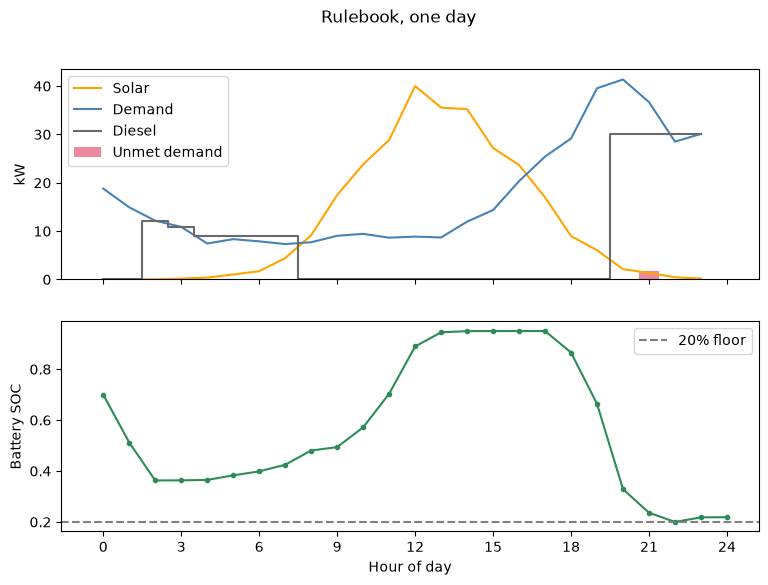

In [2]:
# Run the rulebook for one day (seed 0, same day as notebook 01) and plot the result
day = run_episode(env, rulebook, episode_idx=0)
plot_day(day, env.bat_cfg["initial_soc"], env.bat_cfg["min_soc"], title="Rulebook, one day")
plt.show()

**What this shows:** the rulebook keeps the lights on, with only a sliver of unmet demand around 9 pm, but it burns diesel for 10 of 24 hours. Its weak spot is sunset: because solar is still above 5 kW at 6–7 pm, rule 1 keeps choosing `solar_only`, and the battery drains from 95% to 33% in two hours. By the time the real peak arrives at 8 pm, the battery is nearly empty and the generator runs flat-out until midnight. The rule reacts to the sun that's there now, with no view of the demand coming next.

## Twenty days of results

One day can be a fluke, so we run the rulebook over 20 simulated days (each with different weather and demand noise) and compare it with an operator that picks actions at random, which serves as a floor. Unmet demand here counts energy: kWh not served, including deliberately shed load, as a share of kWh demanded.

In [3]:
# Run rulebook and random operators for 20 days each, then summarise per-day metrics
import pandas as pd
from minigrid_mdp.agents import RandomAgent

N_DAYS = 20

def run_days(env, agent, n_days):
    return pd.concat([run_episode(env, agent, episode_idx=ep) for ep in range(n_days)], ignore_index=True)

def summarise(log):
    shed_kw = log.curtailed_kw.where(log.action == 4, 0.0)
    log = log.assign(unserved_kw=log.unmet_load_kw + shed_kw)
    per_day = log.groupby("episode")
    return pd.DataFrame({
        "diesel_hours_pct": per_day.diesel_on.mean() * 100,
        "fuel_cost_usd":    -per_day.rew_fuel.sum(),
        "unmet_pct":        per_day.unserved_kw.sum() / per_day.load_kw.sum() * 100,
        "end_soc":          per_day.soc_after.last(),
        "reward":           per_day.reward.sum(),
    })

results = {
    "rulebook": summarise(run_days(env, rulebook, N_DAYS)),
    "random":   summarise(run_days(env, RandomAgent(env.action_space), N_DAYS)),
}
summary = pd.concat({name: df.agg(["mean", "std"]).T for name, df in results.items()}, axis=1).round(2)
summary

rulebook        random       
                     mean   std    mean    std
diesel_hours_pct    38.96  2.04   42.29   6.24
fuel_cost_usd       33.52  1.61   39.66   7.02
unmet_pct            0.08  0.28   15.41   6.55
end_soc              0.33  0.06    0.36   0.22
reward             -34.38  3.04 -186.44  51.91

**What this shows:** over 20 days, the rulebook runs diesel 39% of hours and spends about $34 a day on fuel, while leaving less than 0.1% of demand unserved. A random operator, by comparison, leaves 15% of demand unserved. These rulebook numbers are the benchmark the AI has to beat.

One caveat: the rulebook starts each day with the battery at 70% and ends at around 33%. Some of its performance comes from spending stored energy it never replaces, a "free lunch" that comes from simulating one day at a time. Notebook 05 closes that loophole for every operator.

For reference, the originally published version of this project (v1) reported 62% diesel hours for the rulebook. Those numbers came from a simulation where the solar array produced only 7.2 kW at peak instead of 40 kW. See the project README for the corrections.

## Summary

- The rulebook follows four fixed rules based on only two readings, solar output and battery level. It has no sense of time of day or what demand is coming.
- Its blind spot is sunset: it keeps running on battery while a little sun remains, then has to run diesel flat-out through the evening peak.
- Over 20 days it uses diesel 39% of hours, spends about $34/day on fuel, and leaves under 0.1% of demand unserved. That's the benchmark.
- It also ends each day with less stored energy than it started with, a loophole notebook 05 will close.

**Next:** notebook 03 hands the same grid to an AI agent that learns by trial and error, and shows the first thing it learned: how to cheat.